In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Exploratory Data Analysis (EDA)

In [ ]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns = iris.feature_names)

df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

In [ ]:
print(df.head())
print(df.describe())
print(df.groupby("species").mean())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000  

/tmp/ipykernel_2433/3219351687.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby("species").mean())


**Feature Scaling**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("species", axis = 1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Standardization transforms the features to a comparable scale, generally with a mean of zero and standard deviation of one. The scaler is fitted only on the training data and then applied to both datasets, preventing information from the test set from influencing preprocessing.

**Training the KNN Model**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)
print("Predictions: ", y_pred)

Predictions:  ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


**Confusion Matrix and Accuracy Score**

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)
print("Confusion Matrix: \n", cm)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)

Confusion Matrix: 
 [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Accuracy:  0.9333333333333333


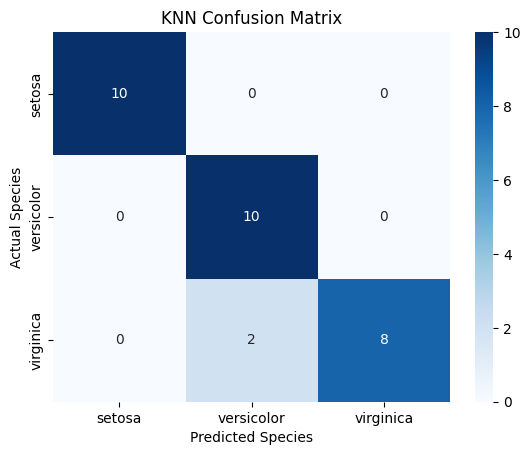

In [ ]:
import seaborn as sns
sns.heatmap(cm,
            annot=True,
            cmap="Blues",
            fmt="d",
            xticklabels=iris.target_names,
            yticklabels=iris.target_names
)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("KNN Confusion Matrix")
plt.show()

The confusion matrix compares the actual species with the predicted species. Correct predictions appear along the main diagonal, while off-diagonal values represent misclassifications. The accuracy score measures the proportion of test observations classified correctly.

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



**Comparing Error rate with K values**

K = 20, Error Rate =  0.0333


Text(0, 0.5, 'Error Rate')

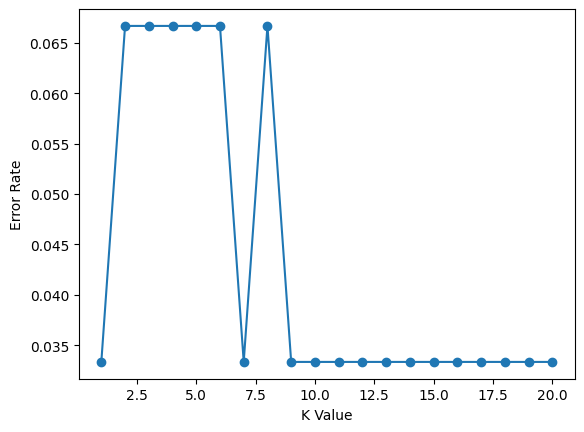

In [ ]:
error_rates = []
for k in range(1, 21):
  model = KNeighborsClassifier(n_neighbors = k)
  model.fit(X_train_scaled, y_train)
  pred = model.predict(X_test_scaled)
  error = np.mean(pred != y_test)
  error_rates.append(error)
print(f"K = {k}, Error Rate = {error: .4f}")
plt.plot(range(1, 21), error_rates, marker = "o")
plt.xlabel("K Value")
plt.ylabel("Error Rate")

The error rate was calculated for values of K ranging from 1 to 20. The error rate represents the proportion of incorrectly classified test observations. Comparing these values helps determine how the number of neighbors affects model performance.

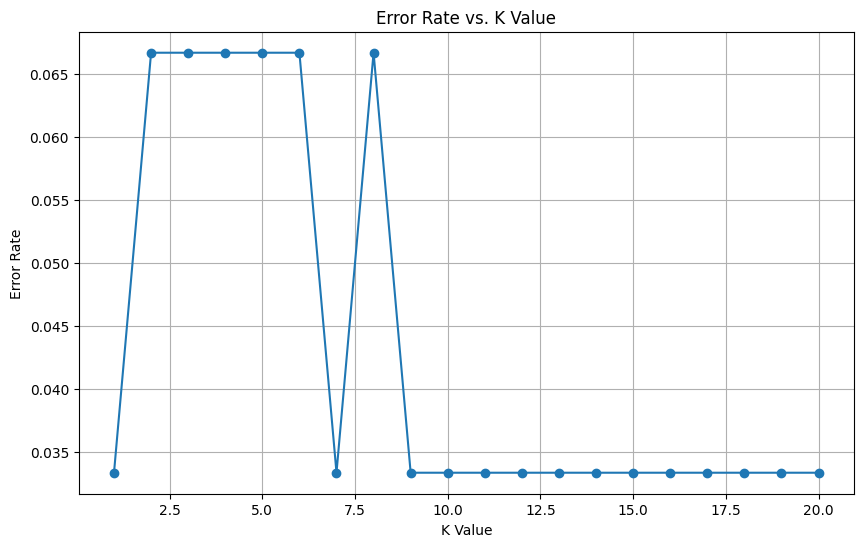

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 21), error_rates, marker='o')
plt.xlabel('K Value')
plt.ylabel('Error Rate')
plt.title('Error Rate vs. K Value')
plt.grid(True)
plt.show()

The graph illustrates the relationship between K and the classification error rate. The minimum point indicates the K value with the lowest observed test error among those evaluated. The graph helps visualize how classification performance changes as more neighbors are considered.

**Finding the Best K**


In [ ]:
best_k = range(1, 21)[np.argmin(error_rates)]
print("Best K: ", best_k)
print("Minimum Error rate: ", min(error_rates))
best_model = KNeighborsClassifier(n_neighbors = best_k)
best_model.fit(X_train_scaled, y_train)
best_predictions = best_model.predict(X_test_scaled)
best_accuracy = accuracy_score(y_test, best_predictions)
print("Best Accuracy: ", best_accuracy)

Best K:  1
Minimum Error rate:  0.03333333333333333
Best Accuracy:  0.9666666666666667


        Actual   Predicted  Correct
0       setosa      setosa     True
1    virginica   virginica     True
2   versicolor  versicolor     True
3   versicolor  versicolor     True
4       setosa      setosa     True
5   versicolor  versicolor     True
6       setosa      setosa     True
7       setosa      setosa     True
8    virginica   virginica     True
9   versicolor  versicolor     True
10   virginica   virginica     True
11   virginica   virginica     True
12   virginica   virginica     True
13  versicolor  versicolor     True
14      setosa      setosa     True


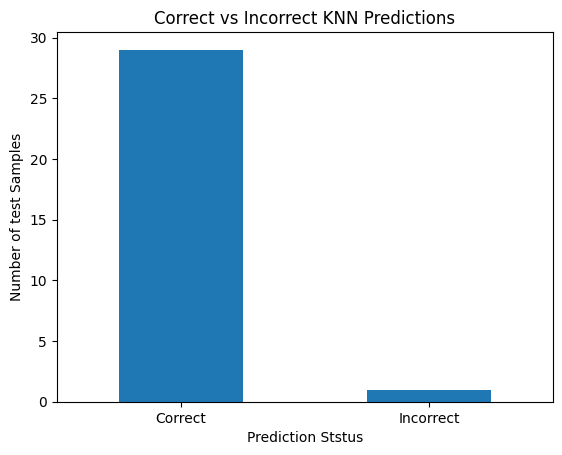

In [ ]:
results = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": pd.Series(best_predictions)
})
results["Correct"] = (
    results["Actual"] == results["Predicted"]
)
print(results.head(15))
results["Correct"].value_counts().plot(
    kind="bar"
)

plt.title("Correct vs Incorrect KNN Predictions")
plt.xlabel("Prediction Ststus")
plt.ylabel("Number of test Samples")
plt.xticks(
    [0, 1],
    ["Correct", "Incorrect"],
    rotation=0
)
plt.show()

The visualization summarizes the correctness of the model's predictions on the test dataset. Correct predictions indicate that the predicted species matches the actual species, while incorrect predictions indicate misclassification. This provides a simple graphical assessment of the classifier's performance.